In [1]:
from cmb_lensing.sample_lcdm import *
from cmb_lensing.simulate import *
from cmb_lensing.constants import *
from cmb_lensing.fisher_forecast import load_sim_cosmology
from scipy.stats import gaussian_kde

c:\Users\zaneb\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


We begin by running a simulation to generate the ground truth data field at the fiducial LCDM cosmology. We set the noise level to $5 \mu$ K-arcmin, resolution to $\theta_\mathrm{pix} = 2.5$ arcminutes per pixel, and look at a single $64 \times 64$ pixel temperature map. The ``lmax`` flag determine the max multipole we run CAMB out to. Past this value, the power spectra are found via log-interpolation.       

In [2]:
#generate a data set with the LCDM parameters held at ground truth
ground_truth_params = load_sim_cosmology(GROUND_TRUTH)
noise_level = 5
data_set = load_sim(nside = 64, theta_pix = 2.5, pol = "I", 
                    master_seed = 42, uk_arcmin_t = noise_level,
                    **ground_truth_params, r = 0, 
                    nt = 0, lmax = 4000)

Now we run the ``sample_joint`` algorithm which takes the data_set as input and outputs samples of the cosmological parameters. Here we only want to look at samples of the single parameter logA, but the current state of ``sample_joint`` allows for joint sampling of 5 of the 6 LCDM parameters (we take a prior value on the optical depth to reionization $\tau_\mathrm{reio} = 0.05$). In general, the more parameters one wants to jointly sample, the stronger the degeneracies between individual parameters become, and we must move to larger and larger map sizes and finer resolutions in order to obtain meaningful samples. The first time you run the following cell, the ~7.9 GB ``camb_grid_spline.npz`` file is downloaded automatically from Hugging Face into the ``camb_splines/`` directory (see the installation page for more on this), so expect a wait. 

In [3]:
#Initialize logA to the total other side of the search range (1-sigma below fiducial)
param_init = dict(GROUND_TRUTH)
param_init["logA"] = PARAM_BOUNDS["logA"][0]

#The 1-D Metropolis Hastings proposal width for each parameter you want to sample
proposal_sigmas = {}
proposal_sigmas["logA"] = 1e-2

#Whether or not to sample each of the LCDM parameters
should_sample = {}
should_sample["logA"] = True
should_sample["ns"] = False
should_sample["ombh2"] = False
should_sample["omch2"] = False
should_sample["theta_MC_100"] = False

#Whether or not to log certain diagnostic statistics
advanced_logging = {}
advanced_logging["phi_acceptance"] = False
advanced_logging["lcdm_acceptance"] = False
advanced_logging["plot_log_pdf"] = True
advanced_logging["plot_lcdm_sigmas"] = True

#Run the sampling algorithm
param_vals, _, _ = sample_joint(data_set, param_init, proposal_sigmas, PARAM_BOUNDS, 
                                should_sample, noise_level, advanced_logging, 
                                fixed_fields = False, phi_init = "ZEROES",
                                iters_per_chain = 300, num_burn_in_fix_theta = 0, 
                                seed = 67, reparameterize_lcdm = False)

downloading camb_grid_spline.npz from huggingface.co/datasets/zaneblood1/5D_LCDM_CAMB_Grid_Spline


C:\Users\zaneb\CMBLensing.py\cmb_lensing\sample_lcdm.py:1302: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


After we get these parameter samples, our next steps are to analyze them. Below we plot the trace of the logA samples differenced with respect to the ground truth value and normalizaed relative to the sigma of the search range for this parameter. We see that there is an initial burn-in as we start far away from the typical set. Then around the 200 point mark, we start sampling from the true distribution of logA and the normalized samples scatter equally within 1 sigma of the ground truth. We can also plot the log(PDF) value of the distribution function we are sampling from. We see that it started to plateau even quicker than the logA trace plot did. This indicates that samples of the unlensed field and lensing potential have a much larger influence on the value of the log(PDF) than does the value of the logA LCDM parameter.

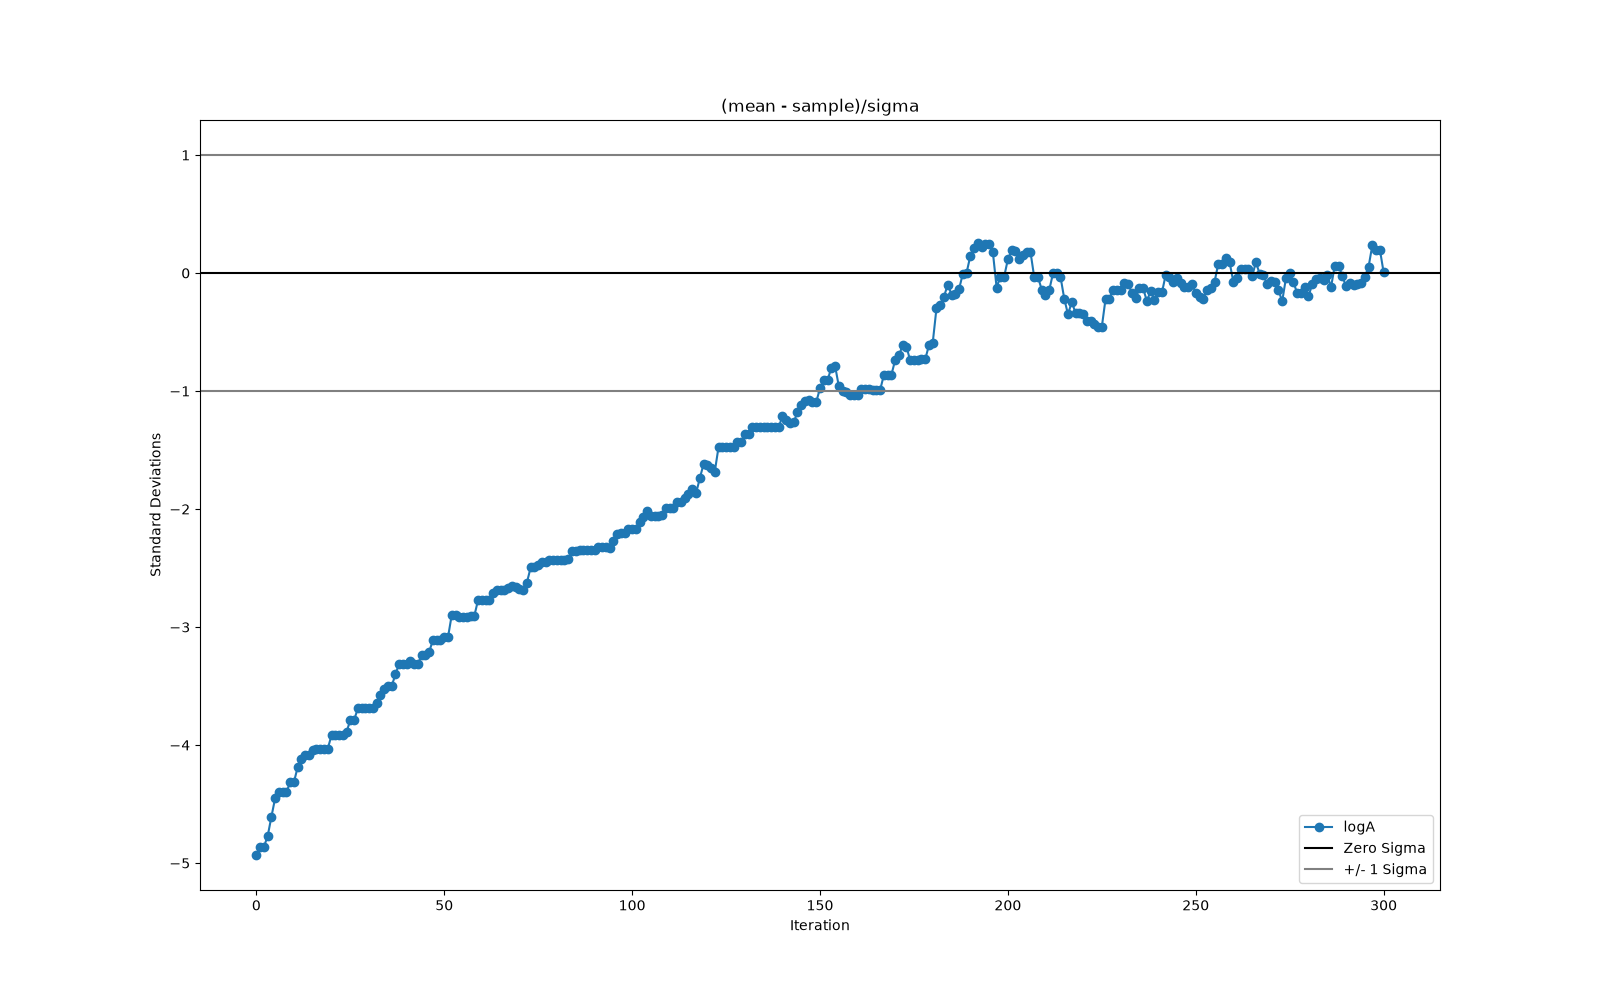

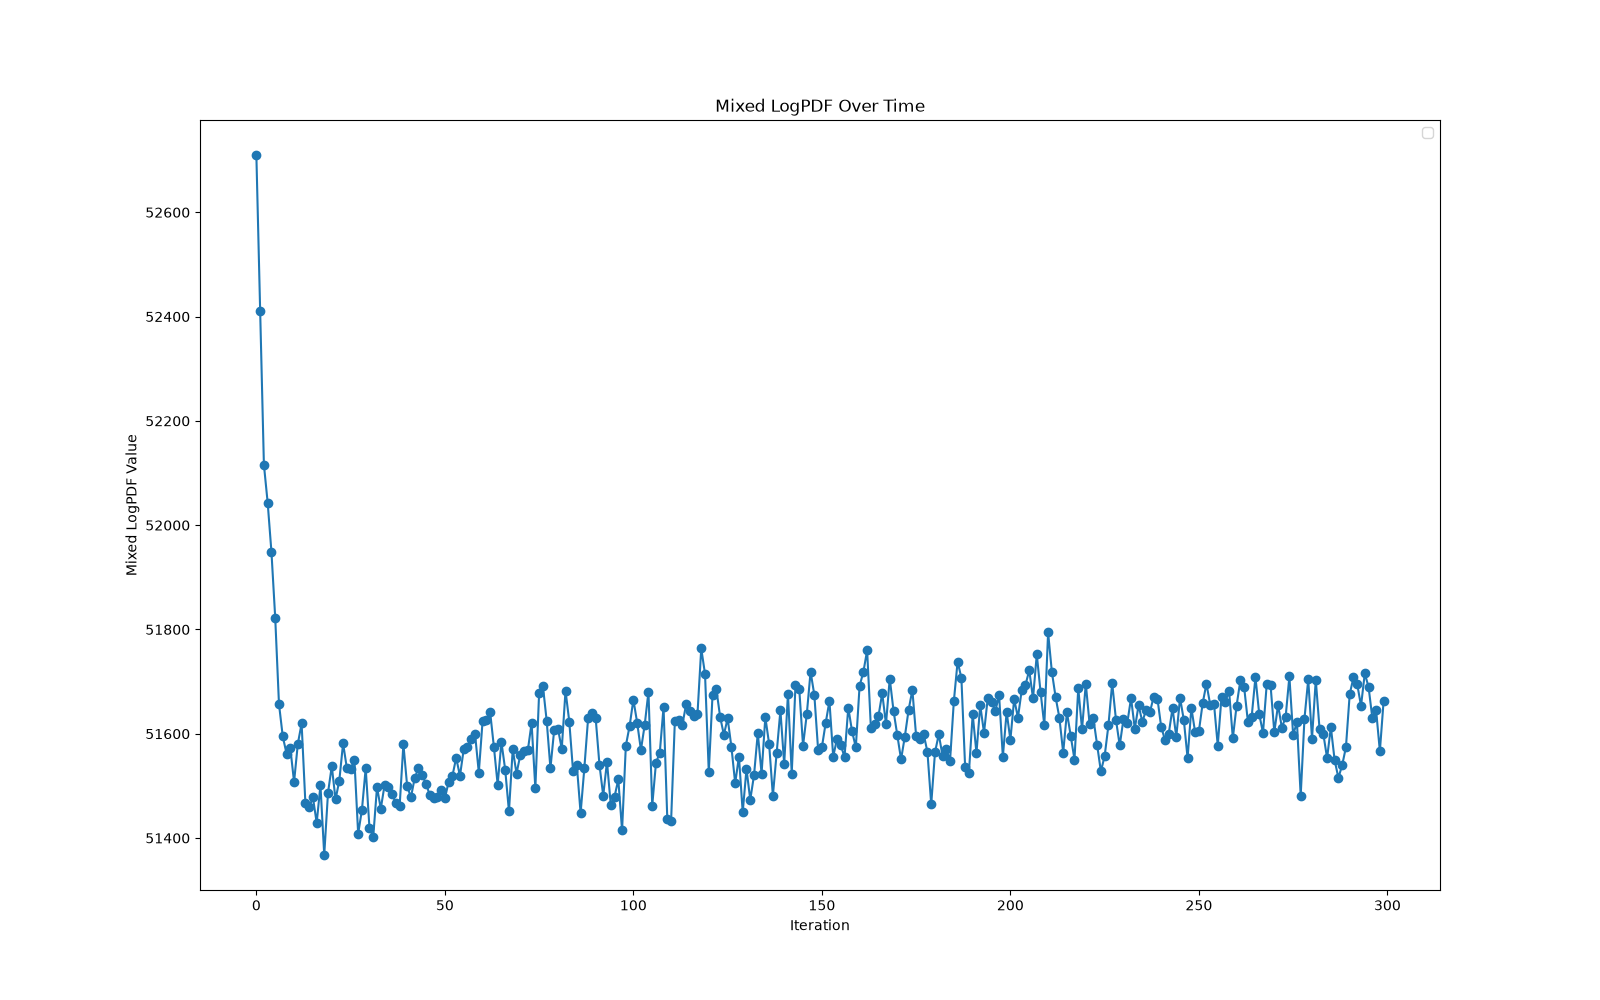

In [4]:
#plot the logpdf history and the logA traces
from IPython.display import Image, display
HERE = os.getcwd()
ONE_UP = os.path.dirname(HERE)
IMAGE_FOLDER = os.path.join(ONE_UP, "cmb_lensing", "sample_lcdm_output")
display(Image(filename = os.path.join(IMAGE_FOLDER, "lcdm_progress.png"), width = 800))
display(Image(filename = os.path.join(IMAGE_FOLDER, "logpdf_progress.png"), width = 800))

We can also plot the UN-normalized trace of the logA samples. The story here is essentially the same: we start at a point in parameter space far away from the ground truth, then slowly burn-in and start sampling from the true logA distribution. Notice that we do not stay fixed on the ground truth value and instead oscillate around it. This is to be expected. Our goal here is to learn the distribution of logA, not necessarily the exact ground truth value. The average scatter of the samples is our way of determining how confident we are in the learned mean. High scatter indicates low confidence and vice versa.

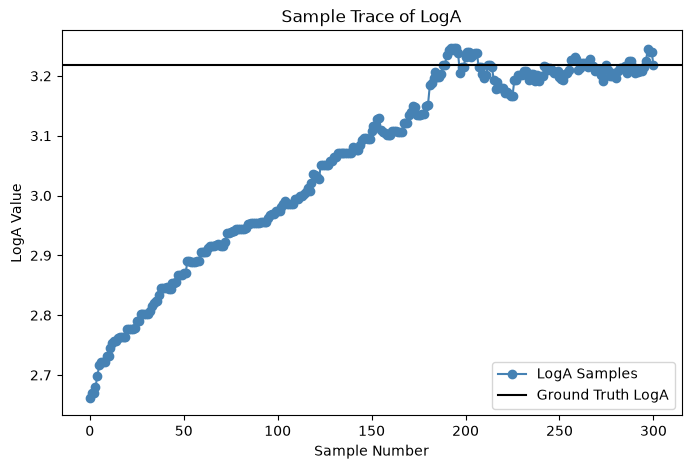

In [5]:
# --------- Trace Plot -----------------------------------------------------------------------------------------------------------------------
%matplotlib inline
plt.figure(figsize = (8, 5))
plt.plot(np.arange(len(param_vals["logA"])), param_vals["logA"], marker = "o", color = "steelblue", label = "LogA Samples")
plt.axhline(GROUND_TRUTH["logA"], color = "black", label = "Ground Truth LogA")
plt.xlabel("Sample Number")
plt.ylabel("LogA Value")
plt.title("Sample Trace of LogA")
plt.legend()
plt.show()

We can also turn these samples into a probability distribution function using e.g. SciPy's ``gaussian_kde`` method. Before we do anything else, we discard the first 175 points or so which are NOT in the typical set. In practice, we should also thin the samples by their integrated autocorrelation time before doing this, but if we were to do that with this relatively short run here, we might not have enough samples to form a distribution. In general, thinning your samples widens your learned distribution, so the kernel density estimate we present here is overconfident relative to what it really should be.

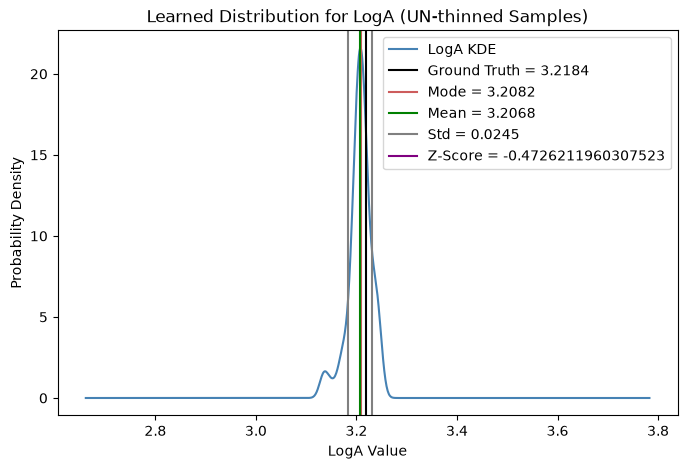

In [6]:
#-------- Gaussian KDE ------------------------------------------------------------------------------------------------------------------------
burn_in = 175
burnt_samples = param_vals["logA"][burn_in:]
grid = np.linspace(PARAM_BOUNDS["logA"][0], PARAM_BOUNDS["logA"][-1], 1000)
dx = np.diff(grid)
log_a_pdf = gaussian_kde(burnt_samples)(grid)

log_a_mode = grid[np.argmax(log_a_pdf)]
log_a_mean = np.dot(log_a_pdf, grid * dx[0])
log_a_std = np.sqrt(np.sum(dx[0] * log_a_pdf * (grid - log_a_mean)**2))

plt.figure(figsize = (8, 5))
plt.plot(grid, log_a_pdf, label = "LogA KDE", color = "steelblue")
plt.axvline(GROUND_TRUTH["logA"], color = "black", label = f"Ground Truth = {round(GROUND_TRUTH["logA"], 4)}")
plt.axvline(log_a_mode, color = "indianred", label = f"Mode = {round(log_a_mode, 4)}")
plt.axvline(log_a_mean, color = "green", label = f"Mean = {round(log_a_mean, 4)}")
plt.axvline(log_a_mean - log_a_std, color = "grey", label = f"Std = {round(log_a_std, 4)}")
plt.axvline(log_a_mean + log_a_std, color = "grey")
plt.plot([], label = f"Z-Score = {(log_a_mean - GROUND_TRUTH["logA"])/log_a_std}", color = "purple")
plt.xlabel("LogA Value")
plt.ylabel("Probability Density")
plt.title("Learned Distribution for LogA (UN-thinned Samples)")
plt.legend()
plt.show()

Now below we plot the autocorrelation function in terms of lag. This tells us how correlated two samples are for points separated by a certain distance. We can then integrate the autocorrelation function to get a single number - the Integrated Autocorrelation Time - which represents how many samples it takes for two points to become completely decorrelated. In our case, this number turns out to be very small, only around $\sim 4$.

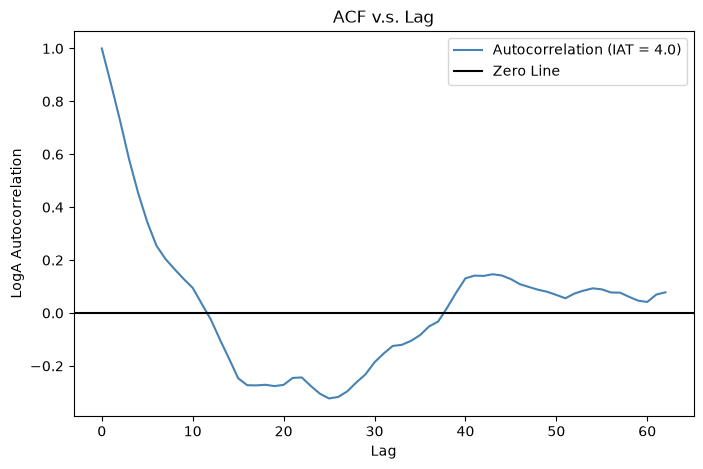

In [7]:
#-------- Autocorrelation Function ------------------------------------------------------------------------------------------------------------
def autocorrelation(chain, max_lag = None):
    """Normalized autocorrelation of a 1D chain of samples."""
    n = len(chain)
    if max_lag is None:
        max_lag = n // 2
    x = chain - np.mean(chain)
    variance = np.var(chain)
    acf = np.correlate(x, x, mode = "full")[n - 1:]  #positive lags only
    acf = acf[:max_lag] / (variance * n)
    return acf

#-------- Integrated Autocorrelation Time -----------------------------------------------------------------------------------------------------
def integrated_autocorrelation_time(acf, c = 5.0):
    """Sokal's automatic windowing — truncate at lag M where M < c * tau(M)."""
    tau = 1.0
    for m in range(1, len(acf)):
        tau += 2.0 * acf[m]
        if m >= c * tau:
            return tau
    return tau

acf = autocorrelation(burnt_samples)
iat = np.ceil(integrated_autocorrelation_time(acf))
plt.figure(figsize = (8, 5))
plt.plot(acf, color = "steelblue", label = f"Autocorrelation (IAT = {iat})")
plt.axhline(0, color = "black", label = "Zero Line")
plt.legend()
plt.ylabel("LogA Autocorrelation")
plt.xlabel("Lag")
plt.title("ACF v.s. Lag")
plt.show()


Here we have drawn samples from a single parameter from a single chain run on a single data map. In practice, one chain on one data map is not a statistically powerful statement due to MCMC noise and cosmic variance (especially on such a small map). The standard workflow is to run the sampling algorithm on multiple different data map realizations at the ground truth cosmology (order 10 - 100 map realizations). For each data map realization when then typically run 5 - 10 sub-chains where we initialize the LCDM parameters to random values for each sub-chain. We then pool samples from the same data maps into a single KDE per map and take the map-wise product of these KDE's to get a single distribution that represents the best estimate we have given all the data for the parameter of interest. For those who are interested in using CMBLensing.py for LCDM parameter inference, the machinery to do big runs like this is laid out in the module ``get_lcdm_samples`` and described in more detail in the codebase's documentation.